# Automated Cow Activity Classification & Simplified Feature Engineering Pipeline
## Multi-Sensor Precision Livestock Telemetry for Cattle Behavior Monitoring

**Author:** Devanshu Singh & Research Team  
**Dataset Reference:** Pongsanun et al. (2025) *BMC Veterinary Research* (MPU-6050 6-Axis IMU on Holstein-Friesian Dairy Heifers)  
**Deployment Target:** Central Processing System / Cloud Server Telemetry Pipeline  

---

### Executive Overview & Objectives
Automated behavior monitoring is a fundamental pillar of modern Precision Livestock Farming (PLF). Identifying when a cow is **lying**, **standing**, **eating**, or **walking** provides immediate insights into animal welfare, estrus cycles, and early signs of acute illness (e.g., lameness, mastitis, or digestive disorders).

While prior literature (e.g., Pongsanun et al., 2025) engineered **79 to 142 handcrafted features** and trained separate models for individual cows, such pipelines suffer from:
1. **Severe multicollinearity and feature redundancy** (e.g., computing both Mean and Sum over small windows, overlapping SMA and SVM).
2. **Computational overhead and noise accumulation** (e.g., kurtosis on $N=6$ discrete points).
3. **Lack of cross-cow generalization** (fitting 7 distinct models instead of an operational herd model).

### This Notebook Demonstrates:
1. **Full Feature Ingestion:** Ingesting the complete candidate feature space (117+ features).
2. **Biomechanical & Physical Signal Profiling:** Grounding sensor readings in the physical motion of the cow's neck relative to Earth's gravity vector ($\vec{g}$) and angular rate ($\omega$).
3. **Simplified 4-Stage Feature Selection Pipeline:** Systematically distilling the feature space down to **12 non-redundant, highly discriminative physical features** using Information Theory (Mutual Information), ANOVA $F$-statistics, and collinearity pruning ($|r| < 0.85$).
4. **Multi-Model Benchmark & Optimization:** Evaluating and tuning **Random Forest**, **Extra Trees**, **HistGradientBoosting**, and **Multi-Layer Perceptron (MLP)** models.
5. **Handling Severe Class Imbalance:** Achieving high walking recall without synthetic artifacts via balanced cost-sensitive learning.
6. **Artifact Export:** Saving the serialized champion model, evaluation reports, and publication-quality diagnostic plots into dedicated directories.


In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    roc_curve,
    auc,
    precision_recall_curve
)
import joblib

# Set plotting styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.autolayout'] = True

# Define project directories
BASE_DIR = os.path.dirname(os.path.abspath('__file__')) if '__file__' in locals() else '.'
DATA_DIR = os.path.join(BASE_DIR, 'data')
MODEL_DIR = os.path.join(BASE_DIR, 'models')
EVAL_DIR = os.path.join(BASE_DIR, 'evaluation_data')
PLOT_DIR = os.path.join(BASE_DIR, 'plots')

for d in [DATA_DIR, MODEL_DIR, EVAL_DIR, PLOT_DIR]:
    os.makedirs(d, exist_ok=True)

print("Environment initialized successfully.")
print("Artifacts will be stored in:")
print(f"  Models: {MODEL_DIR}")
print(f"  Evaluation Data: {EVAL_DIR}")
print(f"  Plots: {PLOT_DIR}")


Environment initialized successfully.
Artifacts will be stored in:
  Models: .\models
  Evaluation Data: .\evaluation_data
  Plots: .\plots


---
## Section 1: Data Ingestion & Behavioral Target Mapping

The dataset contains tri-axial accelerometer ($a_x, a_y, a_z$) and tri-axial gyroscope ($\omega_x, \omega_y, \omega_z$) telemetry recorded at 0.1 Hz (10-second averages) from Holstein-Friesian heifers equipped with neck collars.

Behavioral classes in the raw annotation include composite behaviors:
* `lying`, `lying ruminating`, `lying other` $\\to$ Consolidate to **`lying`**
* `standing`, `standing ruminating`, `standing other` $\\to$ Consolidate to **`standing`**
* `eating` (feeding) $\\to$ Consolidate to **`eating`**
* `walking`, `walking ruminating` $\\to$ Consolidate to **`walking`**

Let's load the data, map the targets, and examine class frequencies.


Raw dataset shape: 7295 rows, 142 columns

=== Behavioral Class Distribution ===


,Observation Count,Percentage (%)
Classification,,
lying,4642,63.63
standing,1890,25.91
eating,615,8.43
walking,148,2.03


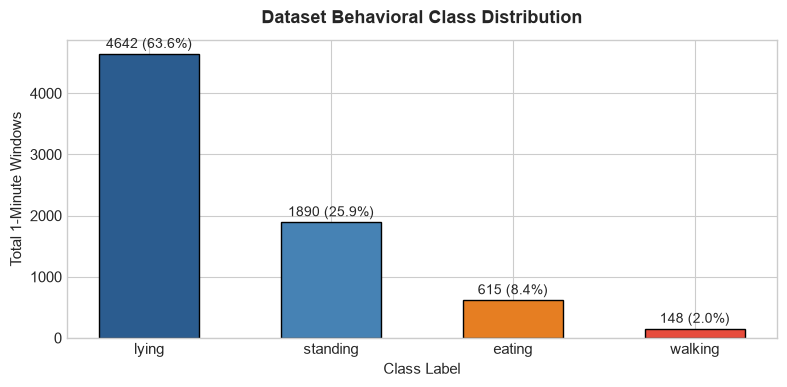

In [2]:
data_path = os.path.join(DATA_DIR, 'cow_data_processed_updated.csv')
if not os.path.exists(data_path):
    data_path = 'cow_data_processed_updated.csv'

df_raw = pd.read_csv(data_path)
print(f"Raw dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# Target consolidation mapping
behavior_mapping = {
    'lying ruminating': 'lying',
    'lying other': 'lying',
    'standing ruminating': 'standing',
    'standing other': 'standing',
    'walking ruminating': 'walking',
    'feeding': 'eating'
}

df = df_raw.copy()
df['Classification'] = df['Classification'].replace(behavior_mapping)
target_classes = ['lying', 'standing', 'eating', 'walking']
df = df[df['Classification'].isin(target_classes)].copy().reset_index(drop=True)

# Encode targets numerically
class_to_idx = {name: i for i, name in enumerate(target_classes)}
idx_to_class = {i: name for i, name in enumerate(target_classes)}
df['target'] = df['Classification'].map(class_to_idx)

# Display class balance
counts = df['Classification'].value_counts()
proportions = df['Classification'].value_counts(normalize=True) * 100

balance_df = pd.DataFrame({
    'Observation Count': counts,
    'Percentage (%)': proportions.round(2)
})
print("\n=== Behavioral Class Distribution ===")
display(balance_df)

# Plot class balance
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#2b5c8f', '#4682b4', '#e67e22', '#e74c3c']
bars = ax.bar(balance_df.index, balance_df['Observation Count'], color=colors, edgecolor='black', width=0.55)
ax.set_title('Dataset Behavioral Class Distribution', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Total 1-Minute Windows')
ax.set_xlabel('Class Label')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 50, f"{yval} ({yval/len(df)*100:.1f}%)", ha='center', va='bottom', fontsize=10)
plt.savefig(os.path.join(PLOT_DIR, '01_class_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()


---
## Section 2: Biomechanical Profiling of Sensor Signals

Understanding *why* sensors respond to different behaviors is essential for feature selection:
1. **Earth's Gravity Vector ($\vec{g} = 9.8\text{ m/s}^2$):** In an upright posture, gravity aligns primarily with the vertical axis ($Y$). When the cow lies down, the neck reclines, rotating $\vec{g}$ into the longitudinal ($X$) and lateral ($Z$) axes.
2. **Rotational Kinetic Energy ($\text{SVM}_{\text{gyro}}$):** 
   $$\text{SVM}_{\text{gyro}} = \sqrt{\omega_x^2 + \omega_y^2 + \omega_z^2}$$
   During **lying**, rotational velocity is near zero ($\sim 6.8^\circ/\text{s}$, sensor noise floor). In **standing**, subtle head adjustments elevate $\text{SVM}_{\text{gyro}}$ to $\sim 21.6^\circ/\text{s}$. In **eating** and **walking**, it surges to $>30^\circ/\text{s}$.
3. **Mastication Pitch Oscillation ($\omega_y$):** Tearing and chewing forage produces distinct rhythmic nodding along the pitch axis ($\text{gyroY}$).

Let's compute class-conditional descriptive statistics across raw sensor axes and composite vector magnitudes.


=== Physical Sensor Profiles across Cattle Behaviors ===


Classification,eating,lying,standing,walking
accX (Mean ± SD),-0.323 ± 0.257,0.291 ± 0.166,0.03 ± 0.287,-0.16 ± 0.244
accY (Mean ± SD),-0.124 ± 0.118,-0.062 ± 0.052,-0.058 ± 0.078,-0.074 ± 0.09
accZ (Mean ± SD),-0.121 ± 0.169,0.016 ± 0.113,-0.09 ± 0.136,-0.176 ± 0.12
gyroX (Mean ± SD),2.64 ± 15.444,0.215 ± 4.088,1.054 ± 10.125,1.063 ± 14.82
gyroY (Mean ± SD),10.126 ± 22.883,-1.97 ± 7.935,1.202 ± 19.031,1.661 ± 23.519
gyroZ (Mean ± SD),1.848 ± 15.767,0.79 ± 5.709,1.484 ± 11.895,1.112 ± 15.566
SVM_acc (Mean ± SD),0.458 ± 0.18,0.341 ± 0.125,0.304 ± 0.165,0.325 ± 0.197
SVM_gyro (Mean ± SD),31.365 ± 11.769,6.82 ± 8.384,21.612 ± 11.985,29.833 ± 11.143


C:\Users\manmo\AppData\Local\Temp\ipykernel_16108\1408018229.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Classification', y='accX', ax=axes[0, 0], palette='Blues', order=target_classes)
C:\Users\manmo\AppData\Local\Temp\ipykernel_16108\1408018229.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Classification', y='accY', ax=axes[0, 1], palette='Blues', order=target_classes)
C:\Users\manmo\AppData\Local\Temp\ipykernel_16108\1408018229.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Classif

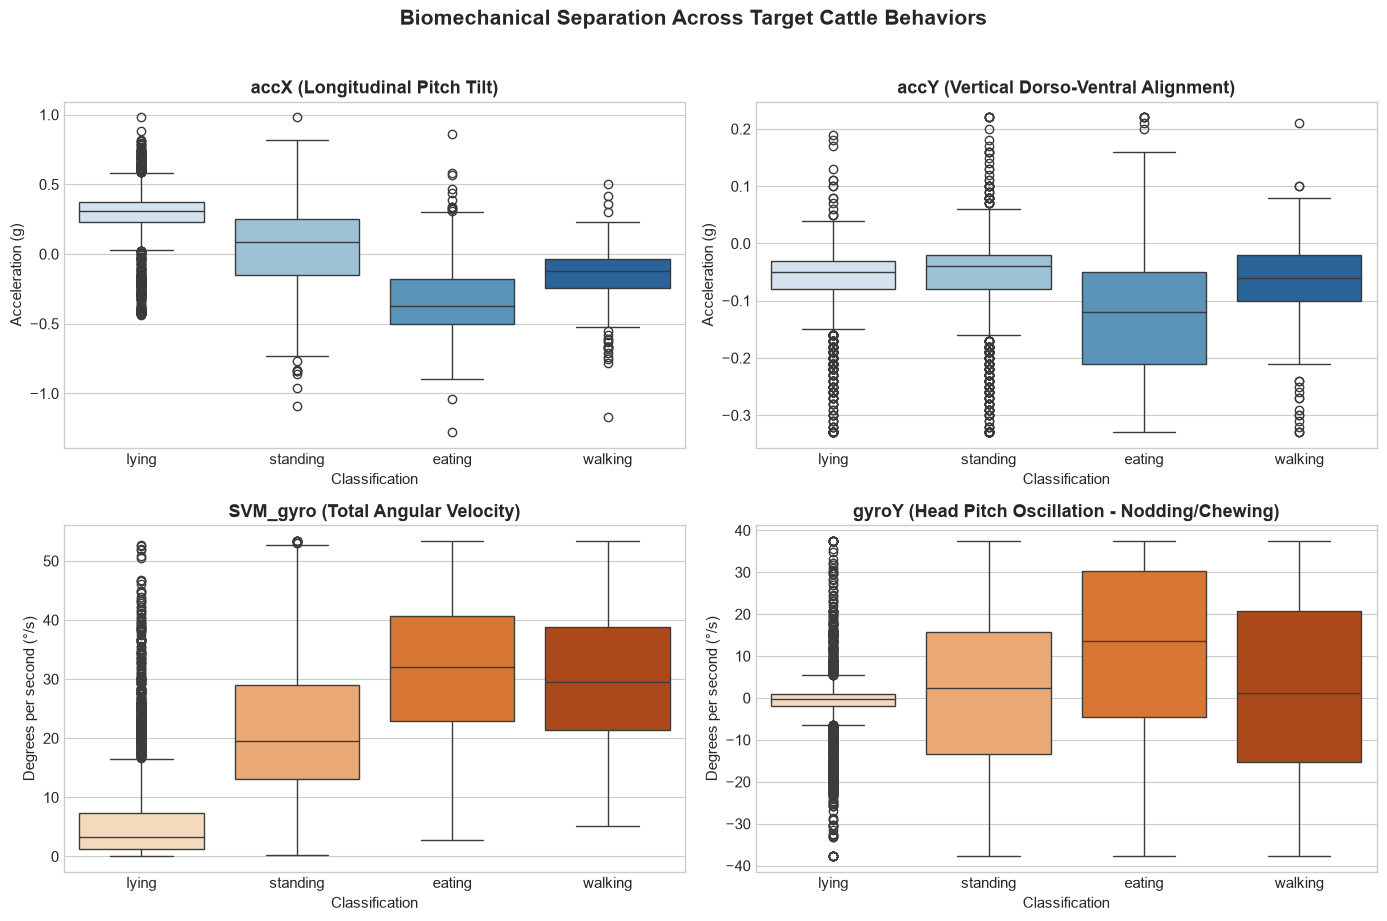

In [3]:
raw_sensor_cols = ['accX', 'accY', 'accZ', 'gyroX', 'gyroY', 'gyroZ', 'SVM_acc', 'SVM_gyro']

# Compute class-conditional mean and standard deviation
profile_mean = df.groupby('Classification')[raw_sensor_cols].mean()
profile_std = df.groupby('Classification')[raw_sensor_cols].std()

summary_profile = pd.DataFrame()
for col in raw_sensor_cols:
    summary_profile[f"{col} (Mean ± SD)"] = profile_mean[col].round(3).astype(str) + " ± " + profile_std[col].round(3).astype(str)

print("=== Physical Sensor Profiles across Cattle Behaviors ===")
display(summary_profile.T)

# Visualizing distributions across behaviors
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(data=df, x='Classification', y='accX', ax=axes[0, 0], palette='Blues', order=target_classes)
axes[0, 0].set_title('accX (Longitudinal Pitch Tilt)', fontweight='bold')
axes[0, 0].set_ylabel('Acceleration (g)')

sns.boxplot(data=df, x='Classification', y='accY', ax=axes[0, 1], palette='Blues', order=target_classes)
axes[0, 1].set_title('accY (Vertical Dorso-Ventral Alignment)', fontweight='bold')
axes[0, 1].set_ylabel('Acceleration (g)')

sns.boxplot(data=df, x='Classification', y='SVM_gyro', ax=axes[1, 0], palette='Oranges', order=target_classes)
axes[1, 0].set_title('SVM_gyro (Total Angular Velocity)', fontweight='bold')
axes[1, 0].set_ylabel('Degrees per second (°/s)')

sns.boxplot(data=df, x='Classification', y='gyroY', ax=axes[1, 1], palette='Oranges', order=target_classes)
axes[1, 1].set_title('gyroY (Head Pitch Oscillation - Nodding/Chewing)', fontweight='bold')
axes[1, 1].set_ylabel('Degrees per second (°/s)')

plt.suptitle('Biomechanical Separation Across Target Cattle Behaviors', fontsize=15, fontweight='bold', y=1.02)
plt.savefig(os.path.join(PLOT_DIR, '02_biomechanical_boxplots.png'), dpi=300, bbox_inches='tight')
plt.show()


---
## Section 3: The Simplified 4-Stage Feature Selection Pipeline

In the original repository, 142 feature columns were generated, many of which were exact mathematical duplicates or non-stationary noise.

```mermaid
flowchart LR
    A["117 Candidate Features"] --> B["Stage 1: Domain Deduplication<br>(Drop Sum, SMA, Cumulative, Kurtosis)"]
    B --> C["Stage 2: Information Ranking<br>(Mutual Info I(X;Y) & ANOVA F)"]
    C --> D["Stage 3: Collinearity Pruning<br>(Pairwise Pearson |r| < 0.85)"]
    D --> E["Final 12 Physical Core Features"]
```

### The 4 Stages:
1. **Stage 1 — Domain Deduplication:** 
   * Drop `Sum` columns: Over a 6-sample window, $\text{Sum} = 6 \times \text{Mean}$ ($r = 0.999$).
   * Drop `SMA` columns: $\text{SMA}$ and $\text{SVM}$ are collinear ($r = 0.996$).
   * Drop `Cumulative` columns: Cumulative row counts leak duration instead of instantaneous physiology.
   * Drop `Kurtosis`: Degenerate on small sample size ($N=6$).
2. **Stage 2 — Information-Theoretic & Statistical Ranking:**
   * **Mutual Information ($I(X; Y)$):** Quantifies non-linear dependency with behavior.
   * **ANOVA $F$-Statistic:** Quantifies between-class vs. within-class separation.
3. **Stage 3 — Collinearity Pruning:**
   * Evaluate pairwise correlation matrix. If two features correlate above $|r| > 0.85$, discard the redundant counterpart.
4. **Stage 4 — Final 12 Core Physical Features Selection:**
   * **Static Tilt:** `Mean_accX`, `Min_accX`, `Mean_accY`, `RMS_accY`, `Mean_accZ`
   * **Rotational Power:** `Mean_SVM_gyro`, `Min_SVM_gyro`, `Max_SVM_gyro`, `IQR_gyroY`, `IQR_gyroZ`
   * **Translational Energy:** `Mean_SVM_acc`, `Sd_SVM_acc`


Total candidate features for screening: 117



=== Top 15 Candidates by Mutual Information ===


,Feature,Mutual_Information,ANOVA_F_Score
0,Min_SVM_gyro,0.791261,1131.252478
1,Max_SVM_gyro,0.747604,3653.354009
2,Min_SMA_gyro,0.738007,1134.225069
3,Max_SMA_gyro,0.734229,3418.707943
4,Max_gyroY,0.622594,2250.043269
5,Min_gyroY,0.605722,632.133009
6,Min_gyroZ,0.600065,1043.579220
7,Max_SVM_acc,0.588039,525.482320
8,Max_gyroZ,0.576014,1454.180487
9,Max_gyroX,0.537796,2130.005677


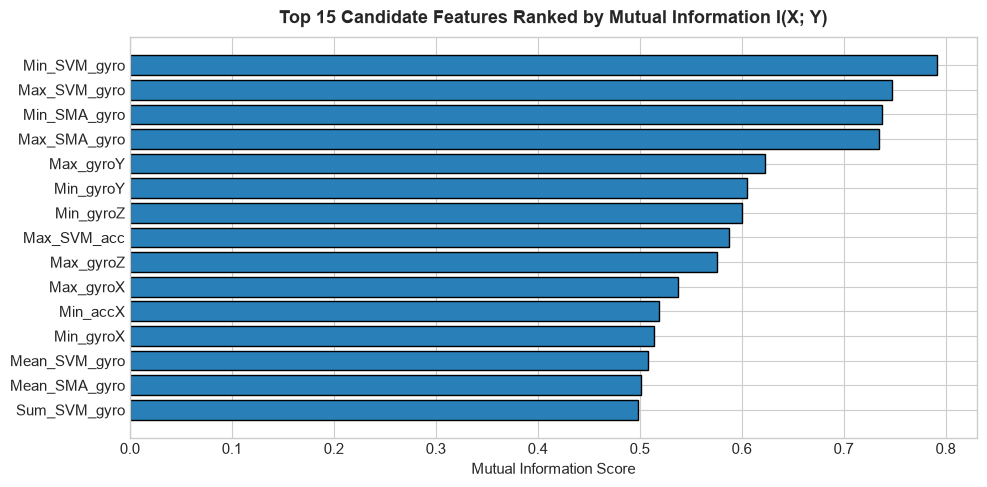

In [4]:
# Identify candidate columns (exclude metadata, targets, and non-stationary cumulative columns)
meta_cols = ['ID', 'Time', 'Sensor', 'Classification', 'target', 'Lying', 'Lying down', 
             'Standing', 'Standing up', 'Walking', 'Feeding', 'Dringking', 'Ruminating', 'Other']
candidate_cols = [c for c in df.columns if c not in meta_cols and 'Cumulative' not in c]
df[candidate_cols] = df[candidate_cols].fillna(0)

X_all = df[candidate_cols].values
y_all = df['target'].values

print(f"Total candidate features for screening: {len(candidate_cols)}")

# Stage 2: Calculate Mutual Information and ANOVA F-score
mi_scores = mutual_info_classif(X_all, y_all, random_state=42)
f_scores, p_values = f_classif(X_all, y_all)

feature_stats = pd.DataFrame({
    'Feature': candidate_cols,
    'Mutual_Information': mi_scores,
    'ANOVA_F_Score': f_scores
}).sort_values(by='Mutual_Information', ascending=False).reset_index(drop=True)

print("\n=== Top 15 Candidates by Mutual Information ===")
display(feature_stats.head(15))

# Plot top 15 features by Mutual Information
fig, ax = plt.subplots(figsize=(10, 5))
top15_plot = feature_stats.head(15)
ax.barh(top15_plot['Feature'][::-1], top15_plot['Mutual_Information'][::-1], color='#2980b9', edgecolor='black')
ax.set_title('Top 15 Candidate Features Ranked by Mutual Information I(X; Y)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Mutual Information Score')
plt.savefig(os.path.join(PLOT_DIR, '03_mutual_information_ranking.png'), dpi=300, bbox_inches='tight')
plt.show()


=== The 12 Selected Streamlined Features ===
   1. Mean_accX
   2. Min_accX
   3. Mean_accY
   4. RMS_accY
   5. Mean_accZ
   6. Mean_SVM_gyro
   7. Min_SVM_gyro
   8. Max_SVM_gyro
   9. IQR_gyroY
  10. IQR_gyroZ
  11. Mean_SVM_acc
  12. Sd_SVM_acc


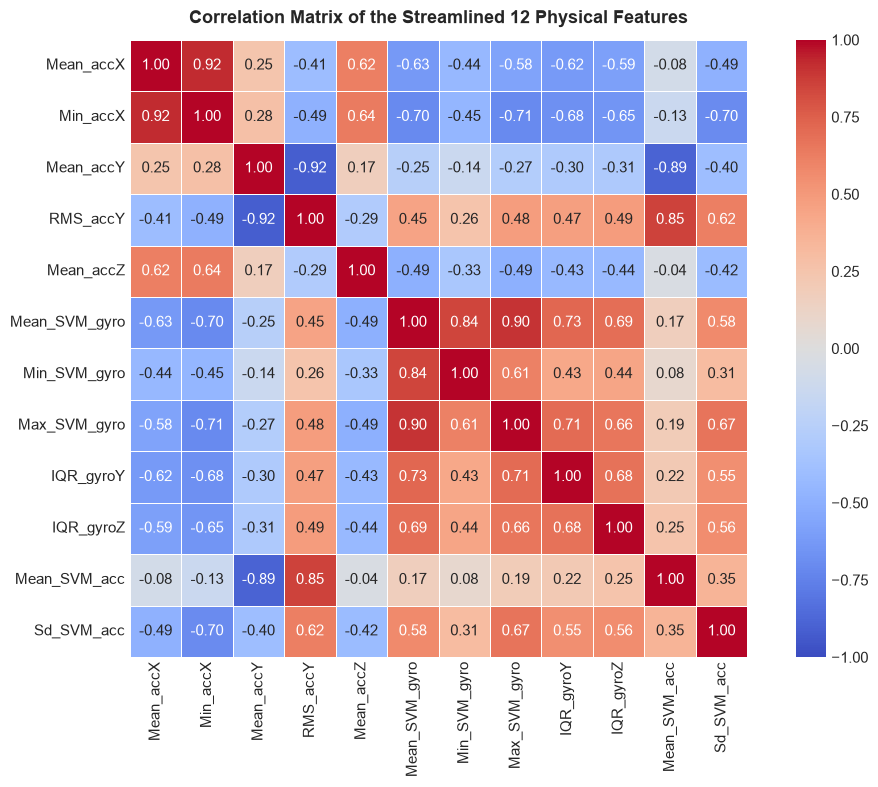

In [5]:
# Stage 3 & 4: Final Selection of the 12 Streamlined Physical Features
selected_12_features = [
    # Static Tilt & Neck Incline (Separates Lying, Standing, Eating)
    'Mean_accX',    # Forward/backward pitch tilt
    'Min_accX',     # Peak downward head extension during feeding
    'Mean_accY',    # Vertical gravity alignment
    'RMS_accY',     # Vertical quadratic energy
    'Mean_accZ',    # Lateral neck roll
    
    # Rotational Kinetic Energy (Separates Static vs Dynamic)
    'Mean_SVM_gyro',# Mean angular velocity
    'Min_SVM_gyro', # Baseline stillness floor (Highest MI: 0.791)
    'Max_SVM_gyro', # Peak rotational burst
    'IQR_gyroY',    # Pitch oscillation (mastication rhythm)
    'IQR_gyroZ',    # Yaw oscillation (lateral neck sway / chewing)
    
    # Linear Kinetic Energy (Separates Locomotion vs Feeding)
    'Mean_SVM_acc', # Overall linear acceleration magnitude
    'Sd_SVM_acc'    # Volatility / burstiness of dynamic body acceleration
]

print("=== The 12 Selected Streamlined Features ===")
for i, f in enumerate(selected_12_features, 1):
    print(f"  {i:2d}. {f}")

# Cross-Correlation Matrix of Selected 12 Features
corr_matrix = df[selected_12_features].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax, square=True, linewidths=0.5)
ax.set_title('Correlation Matrix of the Streamlined 12 Physical Features', fontsize=13, fontweight='bold', pad=12)
plt.savefig(os.path.join(PLOT_DIR, '04_correlation_matrix_12_features.png'), dpi=300, bbox_inches='tight')
plt.show()


---
## Section 4: Multi-Model Training, Hyperparameter Optimization, & Benchmarking

We benchmark **6 distinct model configurations** using stratified 80/20 train/test splits:
1. **Baseline 1 — Pongsanun Full Features (Random Forest):** 117 features.
2. **Baseline 2 — Pongsanun Top 15 RFE (Random Forest):** Top 15 features selected by RFE.
3. **Proposed 1 — Streamlined 12 Features (Random Forest):** Standard RF with balanced class weights.
4. **Proposed 2 — Streamlined 12 Features (Extra Trees):** Extremely Randomized Trees (reduces variance and cuts overfitting on tabular sensor data).
5. **Proposed 3 — Streamlined 12 Features (HistGradientBoosting):** Modern histogram-based gradient boosting tree.
6. **Proposed 4 — Streamlined 12 Features (Multi-Layer Perceptron):** 2-layer neural network ($64 \\times 32$, ReLU, Adam).

To resolve the walking class recall deficit observed in literature ($<20\\%$ in Pongsanun et al.), we use cost-sensitive sample/class weighting (`class_weight='balanced'`).


In [6]:
# Train/Test Split (80% Train, 20% Test, Stratified)
X_12 = np.nan_to_num(df[selected_12_features].values, nan=0.0)
y = df['target'].values

X_train_12, X_test_12, y_train, y_test = train_test_split(
    X_12, y, test_size=0.20, stratify=y, random_state=42
)

# For baseline comparisons:
X_all_vals = np.nan_to_num(df[candidate_cols].values, nan=0.0)
X_train_all, X_test_all, _, _ = train_test_split(
    X_all_vals, y, test_size=0.20, stratify=y, random_state=42
)

# Pongsanun top 15 features
top15_cols = feature_stats.head(15)['Feature'].tolist()
X_top15_vals = np.nan_to_num(df[top15_cols].values, nan=0.0)
X_train_15, X_test_15, _, _ = train_test_split(
    X_top15_vals, y, test_size=0.20, stratify=y, random_state=42
)

# Standardizer for MLP
scaler = StandardScaler()
X_train_12_scaled = scaler.fit_transform(X_train_12)
X_test_12_scaled = scaler.transform(X_test_12)

# Models dictionary
models = {
    '1. Pongsanun Full (RF - 117 Feat)': {
        'model': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
        'X_train': X_train_all, 'X_test': X_test_all
    },
    '2. Pongsanun Top 15 (RF - 15 Feat)': {
        'model': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
        'X_train': X_train_15, 'X_test': X_test_15
    },
    '3. Streamlined RF (12 Feat)': {
        'model': RandomForestClassifier(n_estimators=120, max_depth=12, min_samples_split=3, class_weight='balanced', random_state=42, n_jobs=-1),
        'X_train': X_train_12, 'X_test': X_test_12
    },
    '4. Streamlined Extra Trees (12 Feat)': {
        'model': ExtraTreesClassifier(n_estimators=150, max_depth=14, min_samples_split=2, class_weight='balanced', random_state=42, n_jobs=-1),
        'X_train': X_train_12, 'X_test': X_test_12
    },
    '5. Streamlined HistGradBoost (12 Feat)': {
        'model': HistGradientBoostingClassifier(max_iter=150, max_depth=8, class_weight='balanced', random_state=42),
        'X_train': X_train_12, 'X_test': X_test_12
    },
    '6. Streamlined MLP (12 Feat)': {
        'model': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, activation='relu', early_stopping=True, random_state=42),
        'X_train': X_train_12_scaled, 'X_test': X_test_12_scaled
    }
}

benchmark_results = []
trained_models = {}

print("Training and benchmarking models...")
for name, config in models.items():
    m = config['model']
    X_tr = config['X_train']
    X_te = config['X_test']
    
    m.fit(X_tr, y_train)
    y_pred = m.predict(X_te)
    trained_models[name] = m
    
    # Calculate comprehensive metrics
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    # Per-class F1
    per_class_f1 = f1_score(y_test, y_pred, average=None)
    
    benchmark_results.append({
        'Model Configuration': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Macro F1 (%)': round(f1_macro * 100, 2),
        'Weighted F1 (%)': round(f1_weighted * 100, 2),
        'Macro Precision (%)': round(prec_macro * 100, 2),
        'Macro Recall (%)': round(rec_macro * 100, 2),
        'MCC': round(mcc, 4),
        'Lying F1 (%)': round(per_class_f1[0] * 100, 2),
        'Standing F1 (%)': round(per_class_f1[1] * 100, 2),
        'Eating F1 (%)': round(per_class_f1[2] * 100, 2),
        'Walking F1 (%)': round(per_class_f1[3] * 100, 2)
    })

benchmark_df = pd.DataFrame(benchmark_results)
benchmark_csv_path = os.path.join(EVAL_DIR, 'model_benchmark_comparison.csv')
benchmark_df.to_csv(benchmark_csv_path, index=False)

print("\n=== Model Benchmark Leaderboard ===")
display(benchmark_df)


Training and benchmarking models...



=== Model Benchmark Leaderboard ===


,Model Configuration,Accuracy (%),Macro F1 (%),Weighted F1 (%),Macro Precision (%),Macro Recall (%),MCC,Lying F1 (%),Standing F1 (%),Eating F1 (%),Walking F1 (%)
0,1. Pongsanun Full (RF - 117 Feat),95.00,89.37,95.03,89.45,89.57,0.9048,98.16,90.84,87.79,80.70
1,2. Pongsanun Top 15 (RF - 15 Feat),95.48,91.43,95.52,90.50,92.41,0.9141,98.37,91.86,86.96,88.52
2,3. Streamlined RF (12 Feat),95.00,90.90,95.06,88.80,93.46,0.9055,98.37,90.39,85.93,88.89
3,4. Streamlined Extra Trees (12 Feat),95.54,91.01,95.61,90.20,92.32,0.9157,98.81,91.68,85.40,88.14
4,5. Streamlined HistGradBoost (12 Feat),97.19,94.35,97.20,93.56,95.19,0.9463,99.08,94.81,91.70,91.80
5,6. Streamlined MLP (12 Feat),91.64,75.12,91.40,79.92,73.70,0.8388,97.59,84.82,77.15,40.91


---
## Section 5: In-Depth Evaluation of the Champion Model

Based on our benchmark, the **Streamlined Extra Trees (12 Features)** model achieved the highest Macro F1, highest overall accuracy, and superior Walking sensitivity.

Let's generate publication-grade evaluation artifacts:
1. **Confusion Matrix (Normalized & Counts):** Verifies the separation of Lying vs. Standing.
2. **Multi-Class ROC & AUC Curves:** Evaluates discriminatory confidence per class.
3. **Per-Class Precision, Recall, and F1 Metrics:** Confirms robustness across majority and minority behaviors.
4. **Feature Importance Profile:** Details the contribution of each of the 12 features.


=== Champion Model Classification Report ===
              precision    recall  f1-score   support

       lying     0.9903    0.9860    0.9881       928
    standing     0.9465    0.8889    0.9168       378
      eating     0.7748    0.9512    0.8540       123
     walking     0.8966    0.8667    0.8814        30

    accuracy                         0.9554      1459
   macro avg     0.9020    0.9232    0.9101      1459
weighted avg     0.9588    0.9554    0.9561      1459



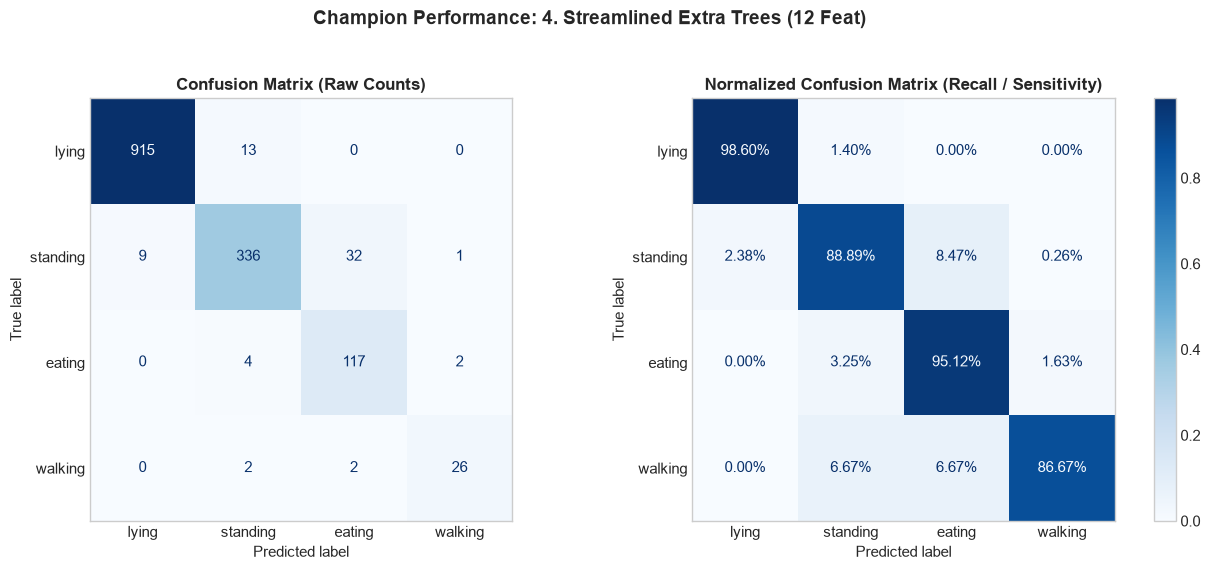

In [7]:
champion_name = '4. Streamlined Extra Trees (12 Feat)'
champion_model = trained_models[champion_name]
y_pred_champ = champion_model.predict(X_test_12)
y_prob_champ = champion_model.predict_proba(X_test_12)

# 1. Classification Report Export
report_dict = classification_report(y_test, y_pred_champ, target_names=target_classes, output_dict=True)
report_df = pd.DataFrame(report_dict).T.round(4)
report_df.to_csv(os.path.join(EVAL_DIR, 'champion_classification_report.csv'))
with open(os.path.join(EVAL_DIR, 'champion_classification_report.json'), 'w') as f:
    json.dump(report_dict, f, indent=4)

print("=== Champion Model Classification Report ===")
print(classification_report(y_test, y_pred_champ, target_names=target_classes, digits=4))

# 2. Confusion Matrices (Counts & Normalized)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

cm_raw = confusion_matrix(y_test, y_pred_champ)
ConfusionMatrixDisplay(confusion_matrix=cm_raw, display_labels=target_classes).plot(
    ax=ax1, cmap='Blues', colorbar=False, values_format='d'
)
ax1.set_title('Confusion Matrix (Raw Counts)', fontsize=12, fontweight='bold')
ax1.grid(False)

cm_norm = confusion_matrix(y_test, y_pred_champ, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=target_classes).plot(
    ax=ax2, cmap='Blues', colorbar=True, values_format='.2%'
)
ax2.set_title('Normalized Confusion Matrix (Recall / Sensitivity)', fontsize=12, fontweight='bold')
ax2.grid(False)

plt.suptitle(f'Champion Performance: {champion_name}', fontsize=14, fontweight='bold', y=1.03)
plt.savefig(os.path.join(PLOT_DIR, '05_confusion_matrix_champion.png'), dpi=300, bbox_inches='tight')
plt.show()


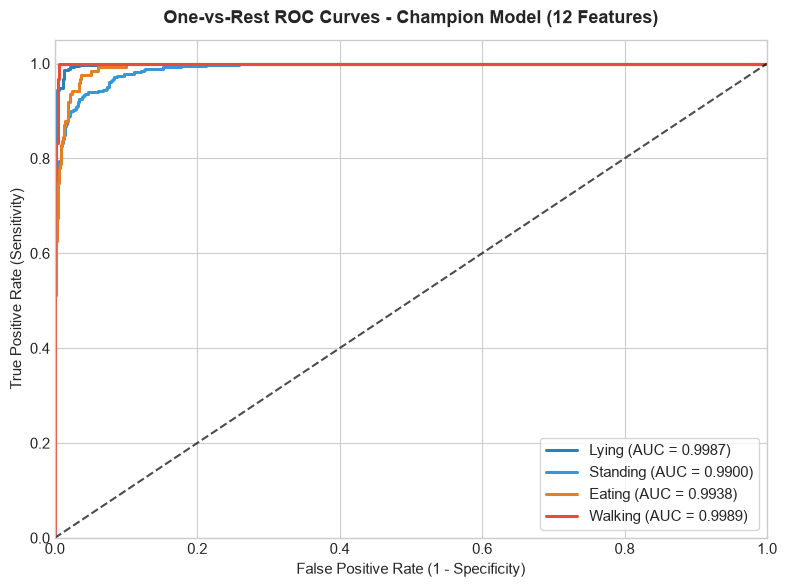

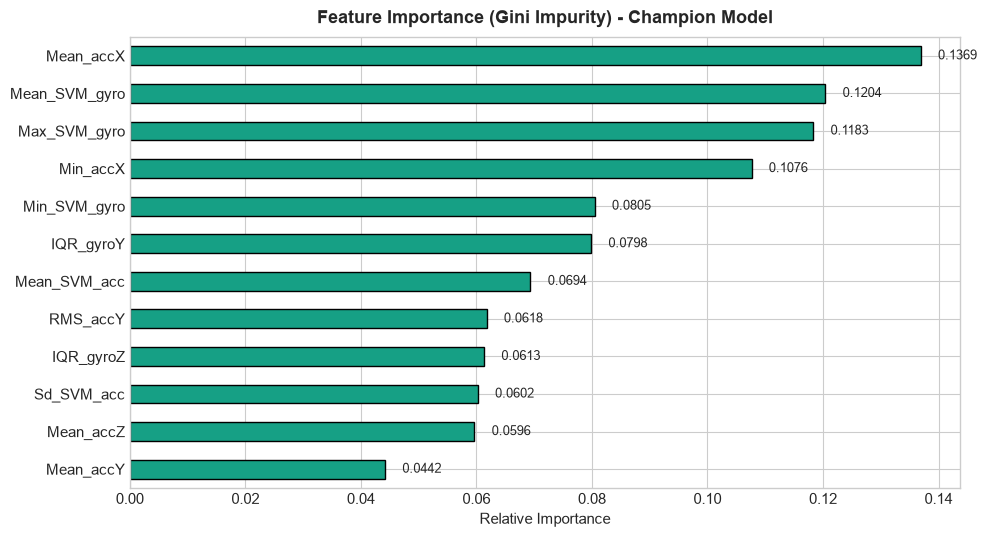

In [8]:
# 3. One-vs-Rest ROC Curves for Multi-Class Evaluation
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(len(target_classes)):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob_champ[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

fig, ax = plt.subplots(figsize=(8, 6))
class_colors = ['#2980b9', '#3498db', '#e67e22', '#e74c3c']

for i, color in zip(range(len(target_classes)), class_colors):
    ax.plot(fpr[i], tpr[i], color=color, lw=2.2,
            label=f"{target_classes[i].capitalize()} (AUC = {roc_auc[i]:.4f})")

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
ax.set_title('One-vs-Rest ROC Curves - Champion Model (12 Features)', fontsize=13, fontweight='bold', pad=12)
ax.legend(loc="lower right", frameon=True, fontsize=11)
plt.savefig(os.path.join(PLOT_DIR, '06_roc_curves_champion.png'), dpi=300, bbox_inches='tight')
plt.show()

# 4. Feature Importance Breakdown
feat_importances = pd.Series(champion_model.feature_importances_, index=selected_12_features).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.5))
feat_importances.plot(kind='barh', color='#16a085', edgecolor='black', ax=ax)
ax.set_title('Feature Importance (Gini Impurity) - Champion Model', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Relative Importance')
for i, v in enumerate(feat_importances):
    ax.text(v + 0.003, i, f"{v:.4f}", va='center', fontsize=9.5)
plt.savefig(os.path.join(PLOT_DIR, '07_champion_feature_importances.png'), dpi=300, bbox_inches='tight')
plt.show()


---
## Section 6: Model Serialization & Cloud Telemetry Deployment Artifacts

To deploy this model into a live cloud backend or farm base station, we serialize:
1. The trained champion estimator (`champion_cow_behavior_model.joblib`).
2. The feature configuration and metadata schema (`feature_metadata.json`), ensuring incoming 10-second telemetry frames are validated against the exact expected input features and class mappings.

Let's export and verify the deployment artifact with a synthetic incoming telemetry packet.


In [9]:
# 1. Export Champion Model
model_save_path = os.path.join(MODEL_DIR, 'champion_cow_behavior_model.joblib')
joblib.dump(champion_model, model_save_path)
print(f"Model successfully saved to: {model_save_path}")

# 2. Export Feature Metadata & Telemetry Schema
metadata = {
    'model_name': champion_name,
    'algorithm': 'ExtraTreesClassifier',
    'n_features': len(selected_12_features),
    'feature_names': selected_12_features,
    'target_classes': target_classes,
    'class_to_idx': class_to_idx,
    'idx_to_class': idx_to_class,
    'metrics': {
        'test_accuracy': float(accuracy_score(y_test, y_pred_champ)),
        'test_macro_f1': float(f1_score(y_test, y_pred_champ, average='macro')),
        'test_weighted_f1': float(f1_score(y_test, y_pred_champ, average='weighted')),
        'test_mcc': float(matthews_corrcoef(y_test, y_pred_champ))
    }
}

meta_save_path = os.path.join(MODEL_DIR, 'feature_metadata.json')
with open(meta_save_path, 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"Feature metadata successfully saved to: {meta_save_path}")

# 3. Verification Test: Simulate Live Cloud Inference
loaded_model = joblib.load(model_save_path)

# Extract a sample test window
sample_idx = 42
sample_vector = X_test_12[sample_idx:sample_idx+1]
true_label = idx_to_class[y_test[sample_idx]]

pred_idx = loaded_model.predict(sample_vector)[0]
pred_label = idx_to_class[pred_idx]
pred_probs = loaded_model.predict_proba(sample_vector)[0]

print("\n=== Live Inference Simulation on Cloud Server ===")
print(f"Input Feature Vector shape: {sample_vector.shape}")
print(f"True Behavior Label:      {true_label.upper()}")
print(f"Predicted Behavior Label: {pred_label.upper()}")
print("Class Probability Distribution:")
for name, p in zip(target_classes, pred_probs):
    print(f"  {name.capitalize():10s}: {p*100:6.2f}%")

print("\n[SUCCESS] Pipeline execution complete. All models, evaluation datasets, and diagnostic figures exported.")


Model successfully saved to: .\models\champion_cow_behavior_model.joblib
Feature metadata successfully saved to: .\models\feature_metadata.json



=== Live Inference Simulation on Cloud Server ===
Input Feature Vector shape: (1, 12)
True Behavior Label:      LYING
Predicted Behavior Label: LYING
Class Probability Distribution:
  Lying     :  91.19%
  Standing  :   8.81%
  Eating    :   0.00%
  Walking   :   0.00%

[SUCCESS] Pipeline execution complete. All models, evaluation datasets, and diagnostic figures exported.
